# Exploratory Data Analysis (EDA) Project
# Phase 2 — 3D Statistical Analysis

**Name:** ANINDO PRITOM BARUA  
**Registration Number:** 23BDS0328  
**Course:** Exploratory Data Analysis (EDA)  
**Dataset:** Indian Food Dataset

## Objective

The objective of this notebook is to perform three-dimensional (3D) statistical analysis on the Indian Food dataset. Three numerical variables will be analyzed simultaneously to identify relationships and patterns that may not be visible in two-dimensional analysis.

Three-dimensional scatter plots, statistical summaries, correlation analysis, and grouped analysis will be used to examine preparation time, cooking time, and total preparation time together.

PHASE 2 - 3D STATISTICAL ANALYSIS

Dataset loaded successfully.
Rows    : 255
Columns : 20

VARIABLES USED FOR 3D ANALYSIS
['prep_time', 'cook_time', 'total_time']

Number of observations: 255

1. THREE-DIMENSIONAL STATISTICAL SUMMARY


,prep_time,cook_time,total_time
count,255.000000,255.000000,255.000000
mean,31.105882,34.529412,65.635294
std,72.554409,48.265650,92.752636
min,-1.000000,-1.000000,-2.000000
25%,10.000000,20.000000,30.000000
50%,10.000000,30.000000,50.000000
75%,20.000000,40.000000,60.000000
max,500.000000,720.000000,730.000000



2. COVARIANCE MATRIX


,prep_time,cook_time,total_time
prep_time,5264.142288,504.668133,5768.810421
cook_time,504.668133,2329.572950,2834.241084
total_time,5768.810421,2834.241084,8603.051505



3. CORRELATION MATRIX


,prep_time,cook_time,total_time
prep_time,1.000000,0.144113,0.857228
cook_time,0.144113,1.000000,0.633100
total_time,0.857228,0.633100,1.000000


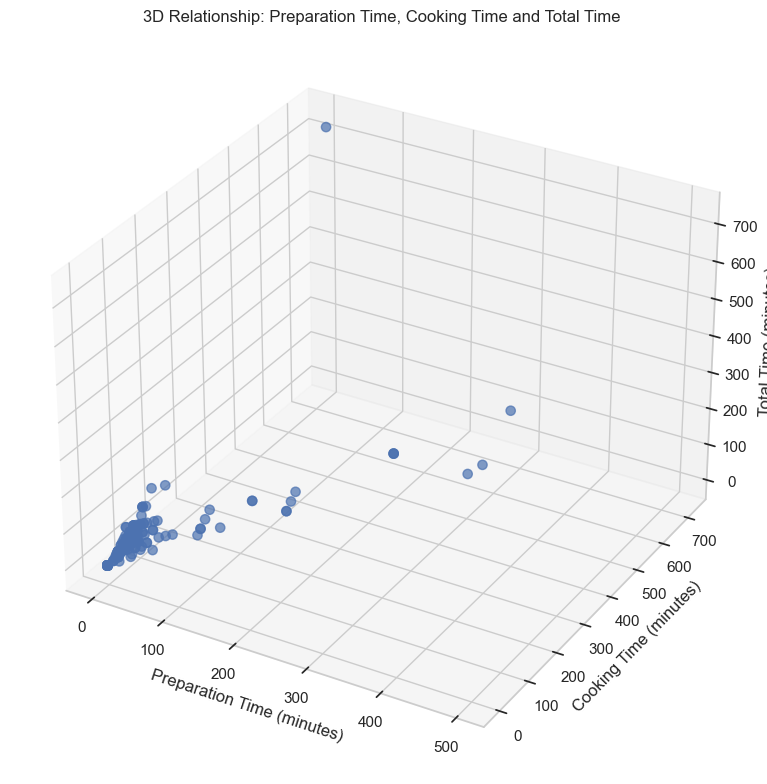

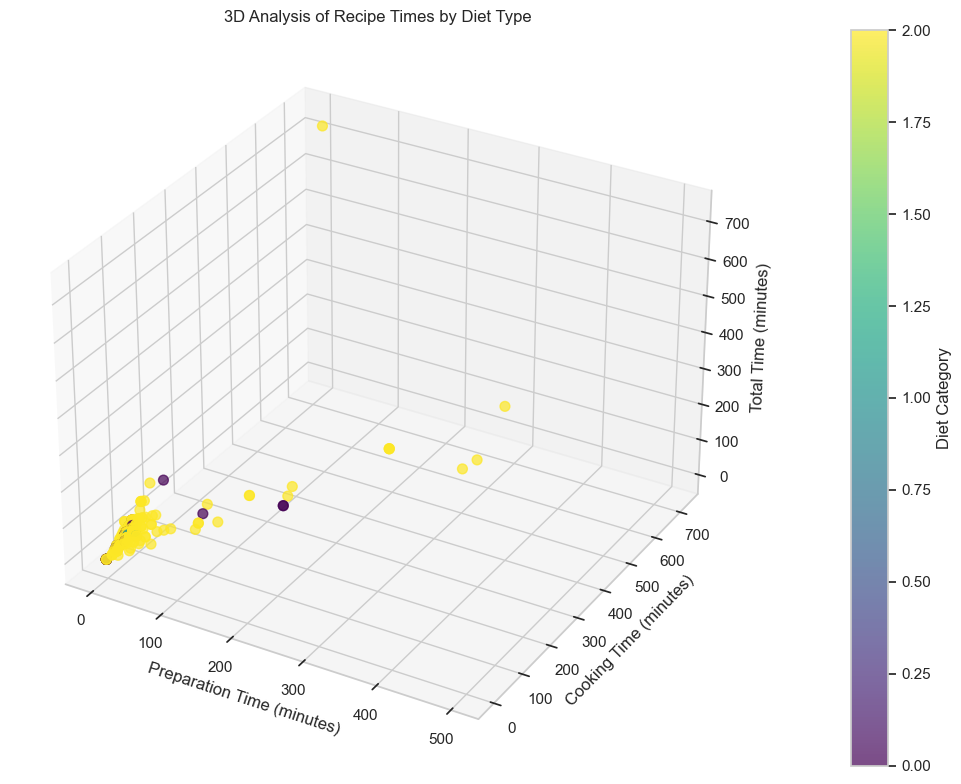

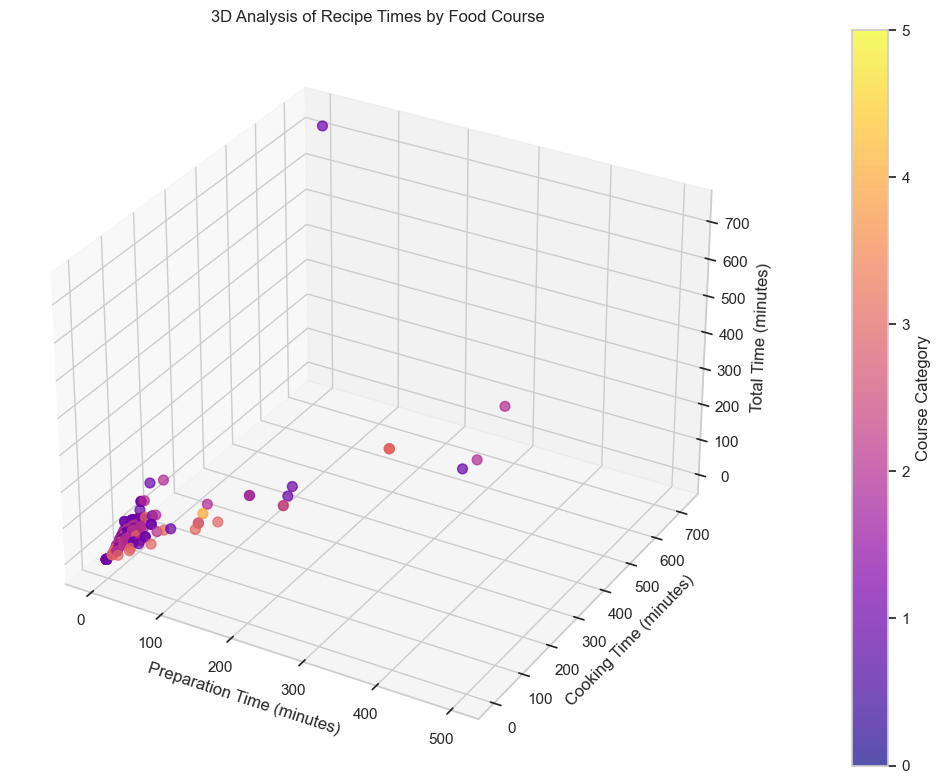

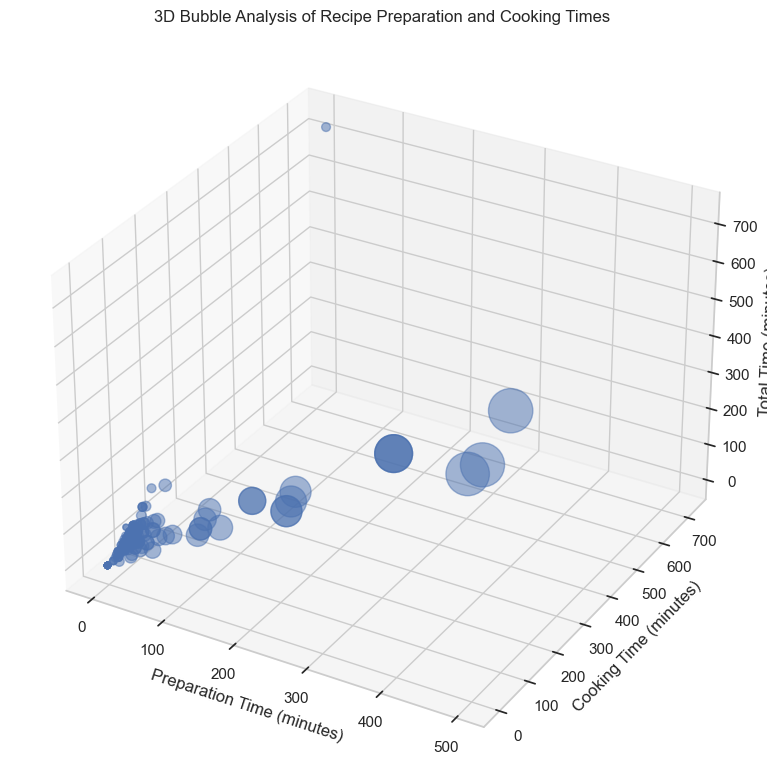


4. 3D GROUPED STATISTICAL ANALYSIS BY DIET


prep_time               cook_time               total_time  \
                    mean median    std      mean median    std       mean   
diet                                                                        
non vegetarian     27.68   10.0  64.11     25.00   27.5  26.85      52.68   
unknown            16.25   12.5   9.46     33.75   32.5  12.50      50.00   
vegetarian         31.80   10.0  74.27     35.74   30.0  50.62      67.54   

                              
               median    std  
diet                          
non vegetarian   42.5  74.46  
unknown          55.0  14.14  
vegetarian       50.0  95.59


5. 3D GROUPED STATISTICAL ANALYSIS BY COURSE


,prep_time,cook_time,total_time
course,,,
?,15.00,30.00,45.00
dessert,27.40,44.08,71.48
main course,25.16,29.93,55.09
snack,51.97,29.10,81.08
starter,180.00,37.50,217.50
unknown,10.00,45.00,55.00



6. TOTAL TIME RELATIONSHIP
Maximum difference between calculated and recorded total time: 0
Total time is exactly equal to preparation time plus cooking time.

FINAL 3D STATISTICAL SUMMARY
Variables analyzed: prep_time, cook_time, total_time
Number of observations: 255

Correlation Matrix:


,prep_time,cook_time,total_time
prep_time,1.000000,0.144113,0.857228
cook_time,0.144113,1.000000,0.633100
total_time,0.857228,0.633100,1.000000



3D STATISTICAL ANALYSIS COMPLETED


In [3]:
# ============================================================
# PHASE 2 - 3D STATISTICAL ANALYSIS
# Name        : ANINDO PRITOM BARUA
# Registration: 23BDS0328
# Dataset     : Indian Food Dataset
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from mpl_toolkits.mplot3d import Axes3D

# ------------------------------------------------------------
# 1. Load the transformed dataset
# ------------------------------------------------------------

file_path = "indian_food_transformed.csv"

df = pd.read_csv(file_path)

print("=" * 75)
print("PHASE 2 - 3D STATISTICAL ANALYSIS")
print("=" * 75)

print("\nDataset loaded successfully.")
print("Rows    :", df.shape[0])
print("Columns :", df.shape[1])

sns.set_theme(style="whitegrid")


# ------------------------------------------------------------
# 2. Select variables for 3D analysis
# ------------------------------------------------------------

variables = [
    "prep_time",
    "cook_time",
    "total_time"
]

analysis_df = df[
    variables + ["diet", "course"]
].dropna()

print("\nVARIABLES USED FOR 3D ANALYSIS")
print("=" * 75)

print(variables)

print("\nNumber of observations:", len(analysis_df))


# ------------------------------------------------------------
# 3. Three-dimensional statistical summary
# ------------------------------------------------------------

print("\n1. THREE-DIMENSIONAL STATISTICAL SUMMARY")
print("=" * 75)

display(
    analysis_df[variables].describe()
)


# ------------------------------------------------------------
# 4. 3D Covariance Matrix
# ------------------------------------------------------------

print("\n2. COVARIANCE MATRIX")
print("=" * 75)

covariance_matrix = analysis_df[
    variables
].cov()

display(covariance_matrix)


# ------------------------------------------------------------
# 5. 3D Correlation Matrix
# ------------------------------------------------------------

print("\n3. CORRELATION MATRIX")
print("=" * 75)

correlation_matrix = analysis_df[
    variables
].corr()

display(correlation_matrix)


# ------------------------------------------------------------
# 6. VISUALIZATION 1
# Basic 3D Scatter Plot
# ------------------------------------------------------------

fig = plt.figure(figsize=(11, 8))

ax = fig.add_subplot(
    111,
    projection="3d"
)

scatter = ax.scatter(
    analysis_df["prep_time"],
    analysis_df["cook_time"],
    analysis_df["total_time"],
    s=45,
    alpha=0.7
)

ax.set_title(
    "3D Relationship: Preparation Time, Cooking Time and Total Time"
)

ax.set_xlabel(
    "Preparation Time (minutes)"
)

ax.set_ylabel(
    "Cooking Time (minutes)"
)

ax.set_zlabel(
    "Total Time (minutes)"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 7. VISUALIZATION 2
# 3D Scatter Plot Colored by Diet
# ------------------------------------------------------------

fig = plt.figure(figsize=(11, 8))

ax = fig.add_subplot(
    111,
    projection="3d"
)

diet_codes = pd.Categorical(
    analysis_df["diet"]
).codes

scatter = ax.scatter(
    analysis_df["prep_time"],
    analysis_df["cook_time"],
    analysis_df["total_time"],
    c=diet_codes,
    cmap="viridis",
    s=50,
    alpha=0.7
)

ax.set_title(
    "3D Analysis of Recipe Times by Diet Type"
)

ax.set_xlabel(
    "Preparation Time (minutes)"
)

ax.set_ylabel(
    "Cooking Time (minutes)"
)

ax.set_zlabel(
    "Total Time (minutes)"
)

plt.colorbar(
    scatter,
    ax=ax,
    pad=0.1,
    label="Diet Category"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 8. VISUALIZATION 3
# 3D Scatter Plot Colored by Course
# ------------------------------------------------------------

fig = plt.figure(figsize=(11, 8))

ax = fig.add_subplot(
    111,
    projection="3d"
)

course_codes = pd.Categorical(
    analysis_df["course"]
).codes

scatter = ax.scatter(
    analysis_df["prep_time"],
    analysis_df["cook_time"],
    analysis_df["total_time"],
    c=course_codes,
    cmap="plasma",
    s=50,
    alpha=0.7
)

ax.set_title(
    "3D Analysis of Recipe Times by Food Course"
)

ax.set_xlabel(
    "Preparation Time (minutes)"
)

ax.set_ylabel(
    "Cooking Time (minutes)"
)

ax.set_zlabel(
    "Total Time (minutes)"
)

plt.colorbar(
    scatter,
    ax=ax,
    pad=0.1,
    label="Course Category"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 9. VISUALIZATION 4
# 3D Scatter with Preparation Time as Bubble Size
# ------------------------------------------------------------

fig = plt.figure(figsize=(11, 8))

ax = fig.add_subplot(
    111,
    projection="3d"
)

bubble_size = (
    analysis_df["prep_time"].clip(lower=0) + 10
) * 2

scatter = ax.scatter(
    analysis_df["prep_time"],
    analysis_df["cook_time"],
    analysis_df["total_time"],
    s=bubble_size,
    alpha=0.5
)

ax.set_title(
    "3D Bubble Analysis of Recipe Preparation and Cooking Times"
)

ax.set_xlabel(
    "Preparation Time (minutes)"
)

ax.set_ylabel(
    "Cooking Time (minutes)"
)

ax.set_zlabel(
    "Total Time (minutes)"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 10. Grouped 3D Statistical Summary
# ------------------------------------------------------------

print("\n4. 3D GROUPED STATISTICAL ANALYSIS BY DIET")
print("=" * 75)

diet_summary = analysis_df.groupby(
    "diet"
)[
    variables
].agg(
    ["mean", "median", "std"]
).round(2)

display(diet_summary)


# ------------------------------------------------------------
# 11. Grouped 3D Statistical Summary by Course
# ------------------------------------------------------------

print("\n5. 3D GROUPED STATISTICAL ANALYSIS BY COURSE")
print("=" * 75)

course_summary = analysis_df.groupby(
    "course"
)[
    variables
].mean().round(2)

display(course_summary)


# ------------------------------------------------------------
# 12. Verify the relationship between Total Time
# and Preparation + Cooking Time
# ------------------------------------------------------------

print("\n6. TOTAL TIME RELATIONSHIP")
print("=" * 75)

calculated_total = (
    analysis_df["prep_time"]
    + analysis_df["cook_time"]
)

difference = (
    analysis_df["total_time"]
    - calculated_total
).abs()

print(
    "Maximum difference between calculated and recorded "
    "total time:",
    difference.max()
)

if difference.max() == 0:
    print(
        "Total time is exactly equal to preparation time "
        "plus cooking time."
    )
else:
    print(
        "Some differences exist between total time and "
        "the sum of preparation and cooking time."
    )


# ------------------------------------------------------------
# 13. Final 3D Summary
# ------------------------------------------------------------

print("\nFINAL 3D STATISTICAL SUMMARY")
print("=" * 75)

print(
    "Variables analyzed:",
    ", ".join(variables)
)

print(
    "Number of observations:",
    len(analysis_df)
)

print("\nCorrelation Matrix:")
display(correlation_matrix)

print("\n" + "=" * 75)
print("3D STATISTICAL ANALYSIS COMPLETED")
print("=" * 75)

## Conclusion

Three-dimensional statistical analysis was successfully performed on the Indian Food dataset using preparation time, cooking time, and total time as the three primary numerical dimensions.

Three-dimensional scatter plots were used to visualize the combined relationships among the variables. Additional visualizations incorporated diet type and food course to provide further categorical context.

Covariance and correlation matrices were calculated to quantify relationships among the three numerical variables, while grouped statistical summaries were used to compare recipe times across diet and course categories.

The analysis also confirmed the mathematical relationship between total time, preparation time, and cooking time. Since total time was derived from preparation time and cooking time, its strong relationship with those variables is expected.

The 3D analysis provides a combined view of multiple variables and completes the statistical analysis section before moving to clustering techniques.